# CS781 Phase 1 — Arch 2: Encoder-decoder Transformer (`ARCH = "bart"`)
One self-contained notebook per architecture, so the 4 notebooks can run **at the same time** on 4 Colab accounts.

| | |
|---|---|
| Model | `BartForConditionalGeneration`, random init |
| Objective | mixture per micro-batch: continuation (encoder reads the prompt, decoder writes the continuation, loss on continuation only) and BART text-infilling denoising (decoder rebuilds a span-masked window) |
| Checkpoints | private repo `<hf-user>/cs781-p1-bart-v2`: `latest/` = resumable training state, `best/` = best validation loss |

**v2 retrain.** The v1 BART run (`cs781-p1-bart`) collapsed: the decoder ignored the encoder and wrote the same
continuation for every prompt. v2 trains into a **new** repo (`cs781-p1-bart-v2`, so v1 stays as report evidence and is
never resumed) and adds BART text-infilling as a second objective, a `<mask>` token, start-of-training wiring checks and
encoder-use measurements at every evaluation. Later phases must load BART from `cs781-p1-bart-v2`.

**Before you start**
1. `00_data_prep.ipynb` has finished once (it creates the private dataset repo `<hf-user>/cs781-p1-data`).
2. Runtime -> Change runtime type -> **T4 GPU**.
3. Secrets (key icon) -> `HF` = the **same** HF write token used in `00_data_prep`, notebook access ON.

**Run all.** Part A trains for `TRAIN_HOURS`; Part B generates on the local held-out set and the official test
prompts and writes `submission.zip`.
- Colab disconnected? Reconnect and **Run all** again: training resumes from `latest/`; if training had already
  finished it goes straight to Part B.
- Another submission later (e.g. different decoding)? Run the cells up to and including *Configuration*, then run
  Part B with a new `RUN_TAG`.

In [1]:
!pip -q install bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 996.6 kB/s eta 0:00:00


In [2]:
ARCH = "bart"   # fixed for this notebook; each architecture has its own notebook

In [3]:
import os, json, math, time, shutil, random, gc
import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

# A failed upload (network blip, Hub hiccup) must not kill a multi-hour run: retry, then log and keep going.
def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

assert torch.cuda.is_available(), "Switch the runtime to a GPU"
print(torch.__version__, torch.cuda.get_device_name(0))
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.18.0


## Configuration — **all values below are YOUR CHOICE** (document them in the report)

In [4]:
DATA_REPO = f"{HF_USER}/cs781-p1-data"
REPO_SUFFIX = "-v2"   # bart "-v2": fresh repo for the retrain; the collapsed v1 run stays in cs781-p1-bart
MODEL_REPO = f"{HF_USER}/cs781-p1-{ARCH}{REPO_SUFFIX}"
WORK = "/content/p1_train" if os.path.isdir("/content") else "/tmp/p1_train"
os.makedirs(WORK, exist_ok=True)

# Data mixing weights per source (sampling probability of each training window)
MIX = {"sc": 0.35, "hc": 0.35, "trib": 0.15, "acts": 0.15}

# Training budget: wall-clock hours of pure training (the LR schedule is fitted to this)
TRAIN_HOURS = 3
CKPT_MINUTES = 30
EVAL_EVERY = 250          # optimizer steps
EVAL_BATCHES_PER_SOURCE = 10

# Optimisation
LR = 6e-4
MIN_LR_FRAC = 0.1
WARMUP_STEPS = 300
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
GRAD_CLIP = 1.0
MICRO_BS = 8
GRAD_ACCUM = 8
DROPOUT = 0.0
SEED = 42

# Sequence lengths
CTX = 1024                 # decoder-only / prefix-LM window
PREFIX_MIN = 64            # prefix-LM: prefix length sampled in [PREFIX_MIN, CTX - 128]
SRC_MIN, SRC_MAX = 128, 768   # bart: encoder length sampled in this range
TGT_LEN = 256              # bart: decoder (continuation) length

# Model sizes
D_MODEL, N_LAYER, N_HEAD, D_FF = 768, 12, 12, 2048
N_KV_HEAD_SWA, SWA_WINDOW = 4, 256                   # mistral_swa only
BART_ENC_LAYERS, BART_DEC_LAYERS, BART_FF = 6, 6, 3072  # bart only

# bart only: every micro-batch is either a denoising batch (BART text infilling) or a continuation batch
P_DENOISE = 0.5            # probability that a micro-batch is a denoising batch
DENOISE_LEN = 512          # tokens per denoising window; the decoder reconstructs all of them (<= 1024 positions)
MASK_RATIO = 0.3           # fraction of each denoising window covered by masked spans (BART paper: 0.3)
SPAN_LAMBDA = 3.0          # masked span length ~ Poisson(SPAN_LAMBDA), min 1; each span -> one <mask> (BART paper: 3)
CONT_END_MARKER = True     # continuation: append <mask> after the prompt, marking where the missing text starts

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Part A — Training
## Data: per-source token memmaps

In [5]:
if not api.file_exists(DATA_REPO, "meta.json", repo_type="dataset"):
    raise RuntimeError(f"{DATA_REPO} has no meta.json yet -- run 00_data_prep.ipynb to completion first "
                       "(with the same HF token as this notebook's `HF` secret).")
data_dir = snapshot_download(DATA_REPO, repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["*.bin", "meta.json", "tokenizer/*"])
meta = json.load(open(f"{data_dir}/meta.json"))
SOURCES = [s for s in meta["sources"] if MIX.get(s, 0) > 0]
weights = np.array([MIX[s] for s in SOURCES], dtype=np.float64); weights /= weights.sum()
bins = {split: {s: np.memmap(f"{data_dir}/{s}_{split}.bin", dtype=np.uint16, mode="r") for s in SOURCES}
        for split in ("train", "val")}
for s in SOURCES:
    print(f"{s:5s} train {len(bins['train'][s])/1e6:8.1f}M  val {len(bins['val'][s])/1e6:6.2f}M  weight {MIX[s]:.2f}")

from transformers import PreTrainedTokenizerFast
tokenizer = PreTrainedTokenizerFast.from_pretrained(f"{data_dir}/tokenizer")
if ARCH == "bart":   # text infilling needs a mask token; it gets the next free id, so every BPE id is unchanged
    tokenizer.add_special_tokens({"mask_token": "<mask>"})
VOCAB, EOS_ID, PAD_ID = len(tokenizer), tokenizer.eos_token_id, tokenizer.pad_token_id
MASK_ID = tokenizer.mask_token_id if ARCH == "bart" else None
print("vocab", VOCAB, "eos", EOS_ID, "pad", PAD_ID, "mask", MASK_ID)

WINDOW = SRC_MAX + TGT_LEN if ARCH == "bart" else CTX

def sample_windows(split, n, length, rng, source=None):
    out = np.empty((n, length), dtype=np.int64)
    srcs = [source] * n if source else rng.choice(SOURCES, size=n, p=weights)
    for i, s in enumerate(srcs):
        arr = bins[split][s]
        j = int(rng.integers(0, len(arr) - length - 1))
        out[i] = arr[j:j + length]
    return torch.from_numpy(out)

# fixed validation windows per source (identical for every run of the same ARCH family)
val_rng = np.random.default_rng(0)
VAL_SET = {s: [sample_windows("val", MICRO_BS, WINDOW, val_rng, source=s) for _ in range(EVAL_BATCHES_PER_SOURCE)]
           for s in SOURCES}
if ARCH == "bart":   # clean validation windows for the denoising loss (corrupted once, in the Objectives cell)
    VAL_DENOISE_CLEAN = {s: [sample_windows("val", MICRO_BS, DENOISE_LEN, val_rng, source=s)
                             for _ in range(min(2, EVAL_BATCHES_PER_SOURCE))] for s in SOURCES}

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

sc    train    252.5M  val   2.70M  weight 0.35
hc    train    396.6M  val   3.67M  weight 0.35
trib  train    250.3M  val   2.78M  weight 0.15
acts  train     75.0M  val   1.14M  weight 0.15
vocab 32001 eos 0 pad 1 mask 32000


## Model (Hugging Face classes, randomly initialised — no pretrained weights)

In [6]:
from transformers import (LlamaConfig, LlamaForCausalLM, MistralConfig, MistralForCausalLM,
                          BartConfig, BartForConditionalGeneration)

def build_model():
    common = dict(vocab_size=VOCAB, bos_token_id=EOS_ID, eos_token_id=EOS_ID, pad_token_id=PAD_ID)
    if ARCH in ("llama", "prefixlm"):
        cfg = LlamaConfig(hidden_size=D_MODEL, intermediate_size=D_FF, num_hidden_layers=N_LAYER,
                          num_attention_heads=N_HEAD, num_key_value_heads=N_HEAD, max_position_embeddings=CTX,
                          attention_dropout=DROPOUT, tie_word_embeddings=True, **common)
        m = LlamaForCausalLM(cfg)
    elif ARCH == "mistral_swa":
        cfg = MistralConfig(hidden_size=D_MODEL, intermediate_size=D_FF, num_hidden_layers=N_LAYER,
                            num_attention_heads=N_HEAD, num_key_value_heads=N_KV_HEAD_SWA,
                            sliding_window=SWA_WINDOW, max_position_embeddings=CTX,
                            attention_dropout=DROPOUT, tie_word_embeddings=True, **common)
        m = MistralForCausalLM(cfg)
    elif ARCH == "bart":
        # embedding rows rounded up to a multiple of 64 (fp16 tensor-core friendly); ids >= VOCAB are never used
        common["vocab_size"] = -(-VOCAB // 64) * 64
        cfg = BartConfig(d_model=D_MODEL, encoder_layers=BART_ENC_LAYERS, decoder_layers=BART_DEC_LAYERS,
                         encoder_attention_heads=N_HEAD, decoder_attention_heads=N_HEAD,
                         encoder_ffn_dim=BART_FF, decoder_ffn_dim=BART_FF, max_position_embeddings=1024,
                         dropout=DROPOUT, attention_dropout=DROPOUT, activation_dropout=0.0,
                         decoder_start_token_id=EOS_ID, forced_bos_token_id=None, forced_eos_token_id=None,
                         scale_embedding=True, tie_word_embeddings=True, **common)
        m = BartForConditionalGeneration(cfg)
    else:
        raise ValueError(ARCH)
    m.config.cs781_arch = ARCH          # read by the generation notebook
    if ARCH == "bart":                  # read by Part B and later phases (prompt format, mask id)
        m.config.cs781_objective = OBJECTIVE
    return m

OBJECTIVE = (dict(p_denoise=P_DENOISE, denoise_len=DENOISE_LEN, mask_ratio=MASK_RATIO, span_lambda=SPAN_LAMBDA,
                  cont_end_marker=CONT_END_MARKER, mask_id=MASK_ID, src_max=SRC_MAX, tgt_len=TGT_LEN)
             if ARCH == "bart" else None)

model = build_model()
n_params = sum(p.numel() for p in model.parameters())
print(f"{ARCH}: {n_params/1e6:.1f}M parameters")
assert 50e6 <= n_params <= 300e6, "Phase-1 rule: 50M-300M parameters"
model = model.cuda()

bart: 125.4M parameters


## Objectives
Prefix-LM: tokens `< P` attend bidirectionally among themselves; tokens `>= P` are causal. Loss only on positions `>= P`
(predicting prefix tokens would leak, since the prefix sees itself bidirectionally).

BART (v2) mixes two objectives, chosen per micro-batch with probability `P_DENOISE`:
* **continuation** (the Phase-1 task): encoder reads `S` prompt tokens (+ `<mask>` if `CONT_END_MARKER`), decoder
  writes the next `TGT_LEN` tokens; decoder starts from `<|endoftext|>` (as in generation).
* **denoising / text infilling** (Lewis et al., 2020): spans with Poisson(`SPAN_LAMBDA`) lengths cover `MASK_RATIO` of
  a `DENOISE_LEN` window, each span is replaced by one `<mask>`, and the decoder rebuilds the clean window. The decoder
  starts from `<mask>`, which tells it "rebuild" rather than "continue". Rebuilding is impossible without reading the
  encoder, so cross-attention and every encoder layer get a training signal from the first step.

v1 trained on continuation alone. There the encoder's only gradient came through cross-attention, and a
decoder can lower continuation loss using its own previous tokens alone. The v1 run ended with a decoder that ignored the
encoder: the same output for every prompt.

In [7]:
def prefix_mask(B, L, P, device):
    i = torch.arange(L, device=device)
    allowed = (i[None, :] <= i[:, None]) | (i[None, :] < P)      # [query, key]
    return allowed[None, None].expand(B, 1, L, L)                  # bool, True = attend

def cont_inputs(batch, S):
    """bart continuation: the S tokens before position SRC_MAX (+ <mask> end marker) -> the TGT_LEN tokens after it."""
    src = batch[:, SRC_MAX - S:SRC_MAX]
    if CONT_END_MARKER:
        src = torch.cat([src, torch.full_like(src[:, :1], MASK_ID)], 1)
    return src.contiguous(), batch[:, SRC_MAX:SRC_MAX + TGT_LEN].contiguous()

def span_mask(n, rng):
    """Boolean mask over n positions: spans of length max(1, Poisson(SPAN_LAMBDA)) at random starts until
    MASK_RATIO of the positions are covered (overlapping spans merge)."""
    m = np.zeros(n, dtype=bool); target = int(round(MASK_RATIO * n))
    while m.sum() < target:
        L = max(1, int(rng.poisson(SPAN_LAMBDA)))
        s = int(rng.integers(0, n - L + 1)); m[s:s + L] = True
    return m

def infill(x, m):
    """Replace every maximal masked run of x by a single <mask> token."""
    run_start = m & ~np.concatenate(([False], m[:-1]))
    keep = ~m | run_start
    out = x[keep].copy(); out[run_start[keep]] = MASK_ID
    return out

def denoise_batch(windows, rng):
    """(B, DENOISE_LEN) clean windows -> right-padded corrupted encoder input, its attention mask, clean labels."""
    corrupted = [infill(w, span_mask(len(w), rng)) for w in windows.numpy()]
    L = max(len(c) for c in corrupted)
    src = torch.full((len(corrupted), L), PAD_ID, dtype=torch.long); att = torch.zeros_like(src)
    for i, c in enumerate(corrupted):
        src[i, :len(c)] = torch.from_numpy(c); att[i, :len(c)] = 1
    return src, att, windows

def denoise_loss(src, att, tgt):
    src, att, tgt = (t.cuda(non_blocking=True) for t in (src, att, tgt))
    dec_in = torch.cat([torch.full_like(tgt[:, :1], MASK_ID), tgt[:, :-1]], 1)   # <mask> start = "rebuild" mode
    return model(input_ids=src, attention_mask=att, decoder_input_ids=dec_in, labels=tgt).loss

def compute_loss(batch, rng, fixed=False):
    batch = batch.cuda(non_blocking=True)
    B, L = batch.shape
    if ARCH in ("llama", "mistral_swa"):
        return model(input_ids=batch, labels=batch).loss
    if ARCH == "prefixlm":
        P = L // 2 if fixed else int(rng.integers(PREFIX_MIN, L - 128))
        labels = batch.clone(); labels[:, :P] = -100
        return model(input_ids=batch, attention_mask=prefix_mask(B, L, P, batch.device), labels=labels).loss
    if ARCH == "bart":
        src, tgt = cont_inputs(batch, SRC_MAX if fixed else int(rng.integers(SRC_MIN, SRC_MAX + 1)))
        return model(input_ids=src, labels=tgt).loss

def train_loss(rng):
    """One training micro-batch -> (loss, number of tokens it actually used, objective name)."""
    if ARCH == "bart" and rng.random() < P_DENOISE:
        windows = sample_windows("train", MICRO_BS, DENOISE_LEN, rng)
        return denoise_loss(*denoise_batch(windows, rng)), MICRO_BS * DENOISE_LEN, "den"
    batch = sample_windows("train", MICRO_BS, WINDOW, rng)
    if ARCH == "bart":
        S = int(rng.integers(SRC_MIN, SRC_MAX + 1))
        src, tgt = cont_inputs(batch.cuda(non_blocking=True), S)
        return model(input_ids=src, labels=tgt).loss, MICRO_BS * (S + TGT_LEN), "cont"
    return compute_loss(batch, rng), MICRO_BS * WINDOW, "lm"

if ARCH == "bart":   # fixed corruption of the denoising validation windows (same for every evaluation)
    _g = np.random.default_rng(1)
    VAL_DENOISE = {s: [denoise_batch(w, _g) for w in VAL_DENOISE_CLEAN[s]] for s in SOURCES}

@torch.no_grad()
def bart_monitor():
    """Measurements showing whether the decoder uses the encoder (the v1 failure). Model must be in eval mode.
    * denoise: validation loss of the denoising objective
    * cont_first32 / cont_first32_shuffled: continuation loss on the first 32 target tokens with the window's own
      prompt vs. another window's prompt; enc_gain_first32 = shuffled - own (about 0 = prompt is ignored)
    * distinct / n_prompts: distinct greedy 32-token continuations for n different validation prompts (1 = identical)"""
    out, own, shuf = {}, [], []
    with torch.autocast("cuda", dtype=torch.float16):
        out["denoise"] = float(np.mean([denoise_loss(*b).item() for s in SOURCES for b in VAL_DENOISE[s]]))
        for s in SOURCES:
            for b in VAL_SET[s][:2]:
                src, tgt = cont_inputs(b.cuda(), SRC_MAX)
                for sv, acc in ((src, own), (src.roll(1, 0), shuf)):
                    logits = model(input_ids=sv, labels=tgt).logits.float()
                    acc.append(F.cross_entropy(logits.transpose(1, 2), tgt, reduction="none")[:, :32].mean().item())
        out["cont_first32"], out["cont_first32_shuffled"] = float(np.mean(own)), float(np.mean(shuf))
        out["enc_gain_first32"] = out["cont_first32_shuffled"] - out["cont_first32"]
        src = torch.cat([cont_inputs(VAL_SET[s][0][:2].cuda(), SRC_MAX)[0] for s in SOURCES])
        gen = model.generate(input_ids=src, attention_mask=torch.ones_like(src), max_new_tokens=32, min_new_tokens=32,
                             do_sample=False, num_beams=1, decoder_start_token_id=EOS_ID, pad_token_id=PAD_ID,
                             eos_token_id=EOS_ID,
                             suppress_tokens=[PAD_ID, MASK_ID] + list(range(VOCAB, model.config.vocab_size)))
    texts = tokenizer.batch_decode(gen, skip_special_tokens=True)
    out["distinct"], out["n_prompts"] = len(set(texts)), len(texts)
    return out, texts[0]

## Sanity checks
* prefix-LM: the mask really is bidirectional on the prefix and causal after it
* bart: `labels` are shifted to `[<|endoftext|>] + labels[:-1]`; the decoder output changes when the encoder input
  changes (cross-attention is wired); text infilling keeps every unmasked token in order and uses one `<mask>` per span

In [8]:
if ARCH == "bart":
    model.eval()
    g = np.random.default_rng(1)
    with torch.no_grad():
        w = sample_windows("val", 2, WINDOW, g).cuda()
        src, tgt = cont_inputs(w, 64)
        dec_in = torch.cat([torch.full_like(tgt[:, :1], EOS_ID), tgt[:, :-1]], 1)
        loss_labels = model(input_ids=src, labels=tgt).loss.item()
        logits = model(input_ids=src, decoder_input_ids=dec_in).logits.float()
        loss_manual = F.cross_entropy(logits.transpose(1, 2), tgt).item()
        assert abs(loss_labels - loss_manual) < 1e-3, f"label shift differs: {loss_labels} vs {loss_manual}"
        src2 = src.clone(); src2[:, 10] = (src2[:, 10] + 1) % MASK_ID
        diff = (model(input_ids=src2, decoder_input_ids=dec_in).logits.float() - logits).abs().max().item()
        assert diff > 1e-6, "decoder output does not depend on the encoder input"
    x = sample_windows("val", 1, DENOISE_LEN, g)[0].numpy()
    assert x.max() < MASK_ID, "data already contains the <mask> id"
    m = span_mask(len(x), np.random.default_rng(2)); c = infill(x, m)
    n_runs = int((m & ~np.concatenate(([False], m[:-1]))).sum())
    assert (c[c != MASK_ID] == x[~m]).all() and (c == MASK_ID).sum() == n_runs
    print(f"bart checks passed: label shift ok, encoder->decoder max |delta logit| {diff:.2e}, "
          f"infilling masked {m.mean():.1%} of {len(x)} tokens in {n_runs} spans -> encoder length {len(c)}")
    print("  corrupted sample:", tokenizer.decode(c[:120]).replace("\n", " ")[:400])

bart checks passed: label shift ok, encoder->decoder max |delta logit| 6.07e-02, infilling masked 30.5% of 512 tokens in 43 spans -> encoder length 399
  corrupted sample: ).].<mask> as provided in section 460HH all moneys received by<mask> on behalf of the corporation in respect of the operations of the [Brihan Mumbai Electric Supply and Transport<mask>]<mask>These words were substituted for the words 'Bombay Electric Supply and Transport Fund' by Maharashtra 25 of<mask>w.e.f. 4.9.1996).] shall be credited<mask> a fund,<mask> be<mask> City of [Brihan Mumbai<mask> a


In [9]:
if ARCH == "prefixlm":
    model.eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        x = sample_windows("val", 2, 64, np.random.default_rng(1)).cuda()
        ref = model(input_ids=x).logits.float()
        a = model(input_ids=x, attention_mask=prefix_mask(2, 64, 0, x.device)).logits.float()
        assert torch.allclose(ref, a, atol=2e-2), "4D mask ignored / misread by this transformers version"
        P = 32; x2 = x.clone(); x2[:, P - 1] = (x2[:, P - 1] + 1) % VOCAB
        b1 = model(input_ids=x, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        b2 = model(input_ids=x2, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        assert (b1[:, 0] - b2[:, 0]).abs().max() > 1e-5, "prefix is not bidirectional"
        x3 = x.clone(); x3[:, 50] = (x3[:, 50] + 1) % VOCAB
        b3 = model(input_ids=x3, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        assert torch.allclose(b1[:, :50], b3[:, :50], atol=2e-2), "suffix is not causal"
    print("prefix-LM mask checks passed")
model.train()

BartForConditionalGeneration(
  (model): BartModel(
    (shared): BartScaledWordEmbedding(32064, 768, padding_idx=1)
    (encoder): BartEncoder(
      (embed_tokens): BartScaledWordEmbedding(32064, 768, padding_idx=1)
      (embed_positions): BartLearnedPositionalEmbedding(1026, 768)
      (layers): ModuleList(
        (0-5): 6 x BartEncoderLayer(
          (self_attn): BartAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
          (final_layer_n

## Optimiser, schedule, checkpoint / resume

In [10]:
decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                         {"params": no_decay, "weight_decay": 0.0}], lr=LR, betas=BETAS, fused=True)
scaler = torch.amp.GradScaler("cuda")

def lr_at(step, max_steps):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = min(1.0, (step - WARMUP_STEPS) / max(1, max_steps - WARMUP_STEPS))
    return LR * (MIN_LR_FRAC + (1 - MIN_LR_FRAC) * 0.5 * (1 + math.cos(math.pi * prog)))

state = {"step": 0, "max_steps": None, "best_val": float("inf"), "history": [], "train_seconds": 0.0, "tokens": 0}
api.create_repo(MODEL_REPO, private=True, exist_ok=True)
if api.file_exists(MODEL_REPO, "latest/state.pt"):
    ck = torch.load(hf_hub_download(MODEL_REPO, "latest/state.pt", token=HF_TOKEN, force_download=True),
                    map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    state = ck["state"]
    print(f"RESUMED from step {state['step']} / {state['max_steps']}")
    del ck
else:
    print("No checkpoint found, starting fresh")

# Every push of latest/ (~1.3 GB with optimizer state) adds a new LFS version to the repo history. Squashing the
# history after each push keeps only the newest latest/ and best/, so 4 repos stay well inside the HF storage quota.
SQUASH_HISTORY = True

def push_latest():
    d = f"{WORK}/latest"; shutil.rmtree(d, ignore_errors=True); os.makedirs(d)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "state": state},
               f"{d}/state.pt")
    json.dump(state["history"], open(f"{d}/history.json", "w"))
    hub_push(lambda: api.upload_folder(folder_path=d, path_in_repo="latest", repo_id=MODEL_REPO,
                                       commit_message=f"latest step {state['step']}"), "latest/")
    if SQUASH_HISTORY:
        hub_push(lambda: api.super_squash_history(repo_id=MODEL_REPO), "history squash", tries=1)

def push_best(val):
    d = f"{WORK}/best"; shutil.rmtree(d, ignore_errors=True)
    model.save_pretrained(d); tokenizer.save_pretrained(d)
    json.dump({"step": state["step"], "val_loss": val, "arch": ARCH, "params": n_params,
               "tokens_seen": state["tokens"], **({"objective": OBJECTIVE} if OBJECTIVE else {})},
              open(f"{d}/cs781_info.json", "w"), indent=2)
    hub_push(lambda: api.upload_folder(folder_path=d, path_in_repo="best", repo_id=MODEL_REPO,
                                       commit_message=f"best step {state['step']} val {val:.4f}"), "best/")

@torch.no_grad()
def evaluate():
    model.eval(); out = {}
    for s in SOURCES:
        losses = []
        for b in VAL_SET[s]:
            with torch.autocast("cuda", dtype=torch.float16):
                losses.append(compute_loss(b, None, fixed=True).item())
        out[s] = float(np.mean(losses))
    out["mean"] = float(np.mean([out[s] for s in SOURCES]))
    sample = None
    if ARCH == "bart":
        mon, sample = bart_monitor(); out.update(mon)
    model.train(); return out, sample

latest/state.pt: reconstructing file:   0%|          |  0.00B / 1.51GB            

latest/state.pt: downloading bytes:           |  0.00B            

RESUMED from step 4145 / 5872


## Training loop
`max_steps` is fixed after measuring throughput on the first steps so the cosine schedule ends at `TRAIN_HOURS`.
`tokens` counts the tokens each micro-batch actually used (bart: prompt + target, or the denoising window).
bart: `loss` mixes both objectives; `cont` / `den` are the per-objective means over the step's micro-batches.
Every evaluation also prints the encoder-use measurements of `bart_monitor` (see the Objectives cell).

In [11]:
rng = np.random.default_rng(SEED + state["step"])
last_ckpt = time.time(); t_seg = time.time(); seg_tokens = 0

while state["max_steps"] is None or state["step"] < state["max_steps"]:
    step = state["step"]
    lr = lr_at(step, state["max_steps"] or 10**9)
    for g in opt.param_groups: g["lr"] = lr
    t0 = time.time(); loss_acc = 0.0; step_tokens = 0; by_obj = {}
    for _ in range(GRAD_ACCUM):
        with torch.autocast("cuda", dtype=torch.float16):
            loss, ntok, obj = train_loss(rng)
        scaler.scale(loss / GRAD_ACCUM).backward()
        loss_acc += loss.item() / GRAD_ACCUM; step_tokens += ntok; by_obj.setdefault(obj, []).append(loss.item())
    scaler.unscale_(opt)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    state["train_seconds"] += time.time() - t0; state["tokens"] += step_tokens; state["step"] += 1
    seg_tokens += step_tokens

    if state["max_steps"] is None and state["step"] == 30:
        sps = 30 / state["train_seconds"]; tps = state["tokens"] / 30
        state["max_steps"] = int(TRAIN_HOURS * 3600 * sps * 0.93)   # ~7% reserved for eval/checkpoint overhead
        print(f"throughput {sps*tps:,.0f} tok/s -> max_steps {state['max_steps']} "
              f"(~{state['max_steps']*tps/1e6:.0f}M tokens)")

    if state["step"] % 25 == 0:
        el = time.time() - t_seg
        per_obj = {k: float(np.mean(v)) for k, v in by_obj.items()}
        objs = "".join(f" {k} {v:.4f}" for k, v in sorted(per_obj.items())) if ARCH == "bart" else ""
        print(f"step {state['step']}/{state['max_steps']} loss {loss_acc:.4f}{objs} lr {lr:.2e} gnorm {gnorm:.2f} "
              f"{seg_tokens/el:,.0f} tok/s  tokens {state['tokens']/1e6:.0f}M")
        state["history"].append({"step": state["step"], "loss": loss_acc, "lr": lr, "tokens": state["tokens"],
                                 **({f"loss_{k}": v for k, v in per_obj.items()} if ARCH == "bart" else {})})

    done = state["max_steps"] is not None and state["step"] >= state["max_steps"]
    if state["step"] % EVAL_EVERY == 0 or done:
        ev, sample = evaluate()
        state["history"].append({"step": state["step"], "eval": ev, "tokens": state["tokens"]})
        print(f"  EVAL step {state['step']}: " + "  ".join(f"{k} {ev[k]:.4f}" for k in SOURCES + ["mean"]))
        if ARCH == "bart":
            print(f"  BART step {state['step']}: denoise {ev['denoise']:.4f}  continuation first-32 loss: own prompt "
                  f"{ev['cont_first32']:.4f}, other prompt {ev['cont_first32_shuffled']:.4f} (enc gain "
                  f"{ev['enc_gain_first32']:+.4f})  distinct greedy outputs {ev['distinct']}/{ev['n_prompts']}")
            print(f"    sample: {sample[:160]!r}")
            if ev["distinct"] == 1:
                print("  !! all prompts gave the same continuation: the decoder is ignoring the encoder (the v1 failure)")
        if ev["mean"] < state["best_val"]:
            state["best_val"] = ev["mean"]; push_best(ev["mean"]); print("  -> new best pushed")
    if time.time() - last_ckpt > CKPT_MINUTES * 60 or done:
        push_latest(); last_ckpt = time.time(); print("  -> checkpoint pushed")

print("TRAINING DONE. best val", state["best_val"])

step 4150/5872 loss 1.7795 cont 2.5254 den 1.5308 lr 1.78e-04 gnorm 1.17 19,569 tok/s  tokens 162M
step 4175/5872 loss 1.8718 cont 2.3914 den 1.5600 lr 1.75e-04 gnorm 1.68 22,549 tok/s  tokens 163M
step 4200/5872 loss 2.2910 cont 2.7301 den 1.5591 lr 1.71e-04 gnorm 0.95 22,428 tok/s  tokens 164M
step 4225/5872 loss 2.6307 cont 2.7657 den 1.6860 lr 1.68e-04 gnorm 0.70 22,164 tok/s  tokens 165M
step 4250/5872 loss 2.1590 cont 2.7331 den 1.5849 lr 1.65e-04 gnorm 0.99 21,872 tok/s  tokens 166M
  EVAL step 4250: sc 3.1549  hc 2.2729  trib 2.7173  acts 2.5886  mean 2.6834
  BART step 4250: denoise 1.6366  continuation first-32 loss: own prompt 2.9403, other prompt 3.6376 (enc gain +0.6973)  distinct greedy outputs 8/8
    sample: ' the Constitution. The Court, therefore, has no power to issue a writ of mandamus or mandamus directing the Union to issue a writ of mandamus or mandamus direct'


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 4275/5872 loss 1.8959 cont 3.0711 den 1.5042 lr 1.62e-04 gnorm 1.36 19,253 tok/s  tokens 166M
step 4300/5872 loss 1.7833 cont 2.4461 den 1.3857 lr 1.59e-04 gnorm 1.15 19,476 tok/s  tokens 167M
step 4325/5872 loss 1.8550 cont 2.6675 den 1.3676 lr 1.56e-04 gnorm 1.12 19,748 tok/s  tokens 168M
step 4350/5872 loss 2.5475 cont 2.8788 den 1.5537 lr 1.54e-04 gnorm 0.83 20,078 tok/s  tokens 169M
step 4375/5872 loss 2.4126 cont 2.6574 den 1.6781 lr 1.51e-04 gnorm 0.91 20,281 tok/s  tokens 170M
step 4400/5872 loss 2.5026 cont 2.8616 den 1.4255 lr 1.48e-04 gnorm 0.87 20,479 tok/s  tokens 171M
step 4425/5872 loss 2.0565 cont 2.6355 den 1.4775 lr 1.45e-04 gnorm 1.09 20,523 tok/s  tokens 172M
step 4450/5872 loss 2.0296 cont 2.5795 den 1.4798 lr 1.42e-04 gnorm 1.12 20,607 tok/s  tokens 173M
step 4475/5872 loss 2.5882 cont 2.7365 den 1.5495 lr 1.40e-04 gnorm 0.82 20,687 tok/s  tokens 174M
step 4500/5872 loss 2.0764 cont 2.4815 den 1.4013 lr 1.37e-04 gnorm 0.95 20,764 tok/s  t

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 4525/5872 loss 2.3198 cont 2.6724 den 1.7322 lr 1.34e-04 gnorm 1.16 20,139 tok/s  tokens 176M
step 4550/5872 loss 2.0678 cont 2.4569 den 1.4195 lr 1.32e-04 gnorm 1.04 20,274 tok/s  tokens 177M
step 4575/5872 loss 2.2295 cont 2.9425 den 1.5165 lr 1.29e-04 gnorm 1.33 20,351 tok/s  tokens 178M
step 4600/5872 loss 1.9595 cont 2.6933 den 1.2257 lr 1.27e-04 gnorm 1.02 20,457 tok/s  tokens 179M
step 4625/5872 loss 1.9198 cont 2.4707 den 1.3689 lr 1.24e-04 gnorm 1.38 20,541 tok/s  tokens 180M
step 4650/5872 loss 2.3395 cont 2.6736 den 1.3373 lr 1.22e-04 gnorm 0.79 20,590 tok/s  tokens 181M
step 4675/5872 loss 2.0745 cont 2.5290 den 1.3170 lr 1.19e-04 gnorm 0.88 20,633 tok/s  tokens 182M
step 4700/5872 loss 1.9522 cont 2.3825 den 1.2349 lr 1.17e-04 gnorm 0.97 20,712 tok/s  tokens 183M
step 4725/5872 loss 1.8528 cont 2.3715 den 1.3341 lr 1.15e-04 gnorm 1.22 20,768 tok/s  tokens 184M
step 4750/5872 loss 1.6717 cont 2.5840 den 1.3676 lr 1.12e-04 gnorm 1.63 20,819 tok/s  t

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 5775/5872 loss 1.8768 cont 2.6588 den 1.0948 lr 6.04e-05 gnorm 1.28 20,228 tok/s  tokens 225M
step 5800/5872 loss 1.8603 cont 2.4689 den 1.2516 lr 6.02e-05 gnorm 1.62 20,248 tok/s  tokens 226M
step 5825/5872 loss 2.0211 cont 2.5646 den 1.1152 lr 6.01e-05 gnorm 1.32 20,275 tok/s  tokens 227M
step 5850/5872 loss 1.5857 cont 2.2864 den 1.1653 lr 6.00e-05 gnorm 1.66 20,312 tok/s  tokens 228M
  EVAL step 5872: sc 3.0634  hc 2.1899  trib 2.6328  acts 2.4815  mean 2.5919
  BART step 5872: denoise 1.2204  continuation first-32 loss: own prompt 2.8543, other prompt 3.5813 (enc gain +0.7271)  distinct greedy outputs 8/8
    sample: ' the Constitution. The Court, therefore, was not justified in holding that the Constitution of India was not a part of the Constitution. The Court, therefore, w'


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
  -> checkpoint pushed
TRAINING DONE. best val 2.5918909221887585


## Loss curves

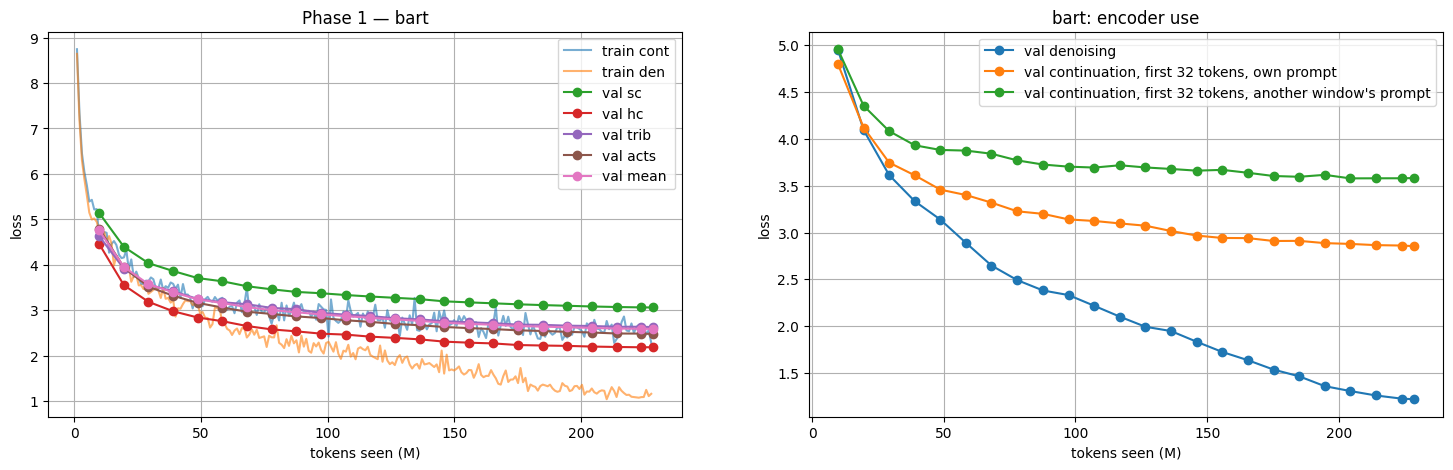

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nt/p1_train/loss_bart.png: 100%|##########|  191kB /  191kB            

Validating                    :           |   0%            

True

In [12]:
import matplotlib.pyplot as plt
h = state["history"]
tr = [(x["tokens"] / 1e6, x["loss"]) for x in h if "loss" in x]
ev = [(x["tokens"] / 1e6, x["eval"]) for x in h if "eval" in x]
fig, axes = plt.subplots(1, 2 if ARCH == "bart" else 1, figsize=(18 if ARCH == "bart" else 10, 5), squeeze=False)
ax = axes[0, 0]
if ARCH == "bart":   # the mixed train loss is not comparable across steps; plot each objective
    for k in ("loss_cont", "loss_den"):
        pts = [(x["tokens"] / 1e6, x[k]) for x in h if k in x]
        if pts: ax.plot(*zip(*pts), label=f"train {k[5:]}", alpha=0.6)
else:
    ax.plot(*zip(*tr), label="train", alpha=0.6)
for s in SOURCES + ["mean"]:
    ax.plot([t for t, _ in ev], [e[s] for _, e in ev], marker="o", label=f"val {s}")
ax.set_xlabel("tokens seen (M)"); ax.set_ylabel("loss"); ax.set_title(f"Phase 1 — {ARCH}"); ax.legend(); ax.grid(True)
if ARCH == "bart":
    ax = axes[0, 1]
    for k, lab in (("denoise", "val denoising"), ("cont_first32", "val continuation, first 32 tokens, own prompt"),
                   ("cont_first32_shuffled", "val continuation, first 32 tokens, another window's prompt")):
        ax.plot([t for t, _ in ev], [e[k] for _, e in ev], marker="o", label=lab)
    ax.set_xlabel("tokens seen (M)"); ax.set_ylabel("loss"); ax.set_title("bart: encoder use"); ax.legend(); ax.grid(True)
plt.savefig(f"{WORK}/loss_{ARCH}.png", dpi=150); plt.show()
hub_push(lambda: api.upload_file(path_or_fileobj=f"{WORK}/loss_{ARCH}.png", path_in_repo=f"loss_{ARCH}.png",
                                 repo_id=MODEL_REPO), "loss plot")

## Free the training model before generation

In [13]:
for _name in ("model", "opt", "scaler", "VAL_SET", "VAL_DENOISE", "VAL_DENOISE_CLEAN", "decay", "no_decay", "loss", "batch"):
    globals().pop(_name, None)
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory still allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

GPU memory still allocated: 0.59 GB


# Part B — Generate, evaluate locally, build submission.zip
1. Generates on the local held-out set (`heldout_prompts.json`) and scores it with the official Phase-1 metrics.
2. Generates on the official test prompts, validates IDs, writes `prediction.json` and `submission.zip`.

Uses the `best/` checkpoint saved by Part A in this session if there is one, otherwise downloads `best/` from the Hub
(so Part B can also be run on its own, or while training is still running on another account).

In [14]:
RUN_TAG = "v1"          # name for this submission (stored in the HF repo with the scores)

# Decoding configurations to compare on the held-out set — YOUR CHOICE.
DECODE_CONFIGS = {
    "greedy_rp1.2": dict(do_sample=False, repetition_penalty=1.2, no_repeat_ngram_size=0),
    "greedy_ngram4": dict(do_sample=False, repetition_penalty=1.0, no_repeat_ngram_size=4),
}
HELDOUT_LIMIT = 400     # how many held-out examples to score per config
TARGET_WORDS = 128
MAX_NEW_TOKENS = 224    # must cover 128 words (check the words/token printout below)
BATCH = 32

In [15]:
import re, zipfile, sys
OUT = f"{WORK}/gen_{RUN_TAG}"
os.makedirs(OUT, exist_ok=True)

## Load model + data

In [16]:
from transformers import AutoConfig, AutoModelForCausalLM, BartForConditionalGeneration, PreTrainedTokenizerFast

if os.path.exists(f"{WORK}/best/cs781_info.json"):     # saved by Part A in this session = newest best
    mdir = f"{WORK}/best"
else:
    mdir = os.path.join(snapshot_download(MODEL_REPO, token=HF_TOKEN, allow_patterns=["best/*"]), "best")
info = json.load(open(f"{mdir}/cs781_info.json")); print(info)
cfg = AutoConfig.from_pretrained(mdir)
arch = getattr(cfg, "cs781_arch", ARCH)
tok = PreTrainedTokenizerFast.from_pretrained(mdir)
EOS_ID, PAD_ID = tok.eos_token_id, tok.pad_token_id
OBJ = getattr(cfg, "cs781_objective", None) or {}       # bart v2: how the prompt was presented in training
END_MARKER, MASK_ID = bool(OBJ.get("cont_end_marker")), OBJ.get("mask_id")
SUPPRESS = [PAD_ID] + ([MASK_ID] if MASK_ID is not None else []) + list(range(len(tok), cfg.vocab_size))
device = "cuda"
if arch == "bart":
    model = BartForConditionalGeneration.from_pretrained(mdir)
    MAX_PROMPT_TOKENS = SRC_MAX                   # encoder prompt length used in training (+ end marker if any)
else:
    model = AutoModelForCausalLM.from_pretrained(mdir)
    MAX_PROMPT_TOKENS = cfg.max_position_embeddings - MAX_NEW_TOKENS
model = model.to(device=device, dtype=torch.float16).eval()
print(arch, f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M params, max prompt tokens {MAX_PROMPT_TOKENS}",
      f"objective {OBJ}" if OBJ else "")

data_dir = snapshot_download(DATA_REPO, repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["heldout_*.json", "meta.json"])
heldout_prompts = json.load(open(f"{data_dir}/heldout_prompts.json", encoding="utf-8"))
heldout_truth = json.load(open(f"{data_dir}/heldout_truth.json", encoding="utf-8"))
keys = list(heldout_prompts)[:HELDOUT_LIMIT] if HELDOUT_LIMIT < len(heldout_prompts) else list(heldout_prompts)
# keep the per-source balance when limiting
if HELDOUT_LIMIT < len(heldout_prompts):
    by_src = {}
    for k in heldout_prompts: by_src.setdefault(k.split("_")[0], []).append(k)
    per = HELDOUT_LIMIT // len(by_src)
    keys = [k for v in by_src.values() for k in v[:per]]

test_path = hf_hub_download("Exploration-Lab/CS-781-Capstone", "Phase_1_Pretraining/Test/test.json",
                            repo_type="dataset", token=HF_TOKEN)
test_data = json.load(open(test_path, encoding="utf-8"))
print("held-out:", len(keys), " test:", len(test_data))

s = [heldout_truth[k]["text"] for k in keys[:100]]
print("tokens per word on references: %.3f" % (sum(len(tok.encode(x)) for x in s) / sum(len(x.split()) for x in s)))

{'step': 5872, 'val_loss': 2.5918909221887585, 'arch': 'bart', 'params': 125442048, 'tokens_seen': 228682120, 'objective': {'p_denoise': 0.5, 'denoise_len': 512, 'mask_ratio': 0.3, 'span_lambda': 3.0, 'cont_end_marker': True, 'mask_id': 32000, 'src_max': 768, 'tgt_len': 256}}


Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

bart 125.4M params, max prompt tokens 768 objective {'cont_end_marker': True, 'denoise_len': 512, 'mask_id': 32000, 'mask_ratio': 0.3, 'p_denoise': 0.5, 'span_lambda': 3.0, 'src_max': 768, 'tgt_len': 256}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

held-out: 373  test: 1000
tokens per word on references: 1.213


## Generation
Prompts are truncated from the **left** (keep the end of the prompt, which is what the continuation follows) and
decoder-only batches are **left-padded**. EOS is blocked until `MAX_NEW_TOKENS` so outputs are never cut short.

In [17]:
from transformers import LogitsProcessorList, RepetitionPenaltyLogitsProcessor, NoRepeatNGramLogitsProcessor

def encode_prompts(prompts):
    ids = [tok.encode(p, add_special_tokens=False)[-MAX_PROMPT_TOKENS:] for p in prompts]
    if END_MARKER:       # bart v2: <mask> after the prompt, as in training
        ids = [x + [MASK_ID] for x in ids]
    L = max(len(x) for x in ids)
    if arch == "bart":   # encoder: right padding
        inp = torch.tensor([x + [PAD_ID] * (L - len(x)) for x in ids])
        att = torch.tensor([[1] * len(x) + [0] * (L - len(x)) for x in ids])
    else:                # decoder: left padding
        inp = torch.tensor([[PAD_ID] * (L - len(x)) + x for x in ids])
        att = torch.tensor([[0] * (L - len(x)) + [1] * len(x) for x in ids])
    return inp.to(device), att.to(device)

@torch.inference_mode()
def prefixlm_generate(inp, att, dc):
    """Prompt = bidirectional prefix (as in training), then causal decoding with the KV cache."""
    B, L = inp.shape
    procs = LogitsProcessorList()
    if dc.get("repetition_penalty", 1.0) != 1.0: procs.append(RepetitionPenaltyLogitsProcessor(dc["repetition_penalty"]))
    if dc.get("no_repeat_ngram_size", 0) > 0: procs.append(NoRepeatNGramLogitsProcessor(dc["no_repeat_ngram_size"]))
    valid = att.bool()
    mask4d = (valid[:, None, None, :] | torch.eye(L, dtype=torch.bool, device=device)[None, None])  # pad queries see themselves
    pos = (att.cumsum(-1) - 1).clamp(min=0)
    out = model(input_ids=inp, attention_mask=mask4d, position_ids=pos, use_cache=True)
    past, logits = out.past_key_values, out.logits[:, -1].float()
    seq, gen, att2d, last_pos = inp, [], att, pos[:, -1]
    for t in range(MAX_NEW_TOKENS):
        scores = procs(seq, logits)
        scores[:, EOS_ID] = -float("inf"); scores[:, PAD_ID] = -float("inf")
        if dc.get("do_sample"):
            probs = torch.softmax(scores / dc.get("temperature", 1.0), -1)
            nxt = torch.multinomial(probs, 1)
        else:
            nxt = scores.argmax(-1, keepdim=True)
        gen.append(nxt); seq = torch.cat([seq, nxt], 1)
        att2d = torch.cat([att2d, torch.ones_like(nxt)], 1); last_pos = last_pos + 1
        out = model(input_ids=nxt, attention_mask=att2d, position_ids=last_pos[:, None], past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[:, -1].float()
    return torch.cat(gen, 1)

@torch.inference_mode()
def generate_batch(prompts, dc):
    inp, att = encode_prompts(prompts)
    if arch == "prefixlm":
        new = prefixlm_generate(inp, att, dc)
    else:
        kw = dict(max_new_tokens=MAX_NEW_TOKENS, min_new_tokens=MAX_NEW_TOKENS, pad_token_id=PAD_ID,
                  eos_token_id=EOS_ID, suppress_tokens=SUPPRESS, **dc)
        out = model.generate(input_ids=inp, attention_mask=att, **kw)
        new = out if arch == "bart" else out[:, inp.shape[1]:]
    texts = []
    for row in new.tolist():
        words = tok.decode(row, skip_special_tokens=True).split()[:TARGET_WORDS]
        texts.append(" ".join(words) if words else "the")   # evaluator rejects empty strings
    return texts

def run(prompt_dict, ids, dc, label):
    preds, t0 = {}, time.time()
    for i in range(0, len(ids), BATCH):
        chunk = ids[i:i + BATCH]
        for k, txt in zip(chunk, generate_batch([prompt_dict[k]["text"] for k in chunk], dc)):
            preds[str(k)] = {"text": txt}
        print(f"\r{label}: {min(i+BATCH, len(ids))}/{len(ids)}  {time.time()-t0:.0f}s", end="")
    print()
    return preds

## Official Phase-1 metrics (same code as `evaluate_phase1.py`)

In [18]:
try:
    import bert_score
except ImportError as e:
    bert_score = None; print("bert-score not importable, BERTScore will be skipped:", e)
from collections import Counter

def lcs_length(a, b):
    if not a or not b: return 0
    if len(a) < len(b): a, b = b, a
    masks = {}
    for j, t in enumerate(a): masks[t] = masks.get(t, 0) | (1 << j)
    state = 0
    for t in b:
        m = masks.get(t, 0); x = m | state; y = (state << 1) | 1; state = x & ~(x - y)
    return bin(state).count("1")

def rouge_l_f1(p, r):
    pt, rt = p.split(), r.split()
    if not pt or not rt: return 0.0
    l = lcs_length(pt, rt)
    if not l: return 0.0
    pp, rr = l / len(pt), l / len(rt)
    return 2 * pp * rr / (pp + rr)

def ngrams(t, n): return Counter(tuple(t[i:i+n]) for i in range(len(t)-n+1)) if len(t) >= n else Counter()

def bleu4(preds, refs):
    clipped = [0]*4; totals = [0]*4; pl = rl = 0
    for p, r in zip(preds, refs):
        pl += len(p); rl += len(r)
        for n in range(1, 5):
            pn, rn = ngrams(p, n), ngrams(r, n); totals[n-1] += sum(pn.values())
            for g, c in pn.items(): clipped[n-1] += min(c, rn.get(g, 0))
    prec = [clipped[i]/totals[i] if totals[i] else 0.0 for i in range(4)]
    if any(x <= 0 for x in prec) or pl == 0: return 0.0
    bp = 1.0 if pl > rl else math.exp(1.0 - rl/pl)
    return bp * math.exp(sum(math.log(x) for x in prec) / 4)

def score(pred, truth):
    ids = list(truth)
    P = [pred[i]["text"].strip() for i in ids]; R = [truth[i]["text"].strip() for i in ids]
    out = {}
    try:   # a BERTScore failure (e.g. library/version clash) must not block writing the submission
        _, _, f = bert_score.score(P, R, lang="en", batch_size=32, verbose=False, device="cuda")
        out["bertscore_f1"] = float(f.mean())
    except Exception as e:
        f = None; print("  !! BERTScore failed, only ROUGE-L / BLEU-4 reported:", repr(e))
    out["rougeL_f1"] = float(np.mean([rouge_l_f1(p, r) for p, r in zip(P, R)]))
    out["bleu4"] = bleu4([p.split() for p in P], [r.split() for r in R])
    for src in sorted({i.split("_")[0] for i in ids}) if f is not None else []:   # per-source BERTScore (report material)
        idx = [j for j, i in enumerate(ids) if i.startswith(src + "_")]
        out[f"bs_{src}"] = float(f[idx].mean())
    return out

## 1) Compare decoding configs on the local held-out set

In [19]:
truth_sub = {k: heldout_truth[k] for k in keys}
# saved so the official checker can be run on them too:  evaluate_phase1.py --truth heldout_truth.json --prediction heldout_pred_<config>.json
json.dump(truth_sub, open(f"{OUT}/heldout_truth.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
results = {}
for name, dc in DECODE_CONFIGS.items():
    preds = run(heldout_prompts, keys, dc, name)
    json.dump(preds, open(f"{OUT}/heldout_pred_{name}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    results[name] = score(preds, truth_sub)
    results[name]["distinct_outputs"] = len({v["text"] for v in preds.values()})
    print(name, {k: round(v, 4) for k, v in results[name].items()}, f"(of {len(preds)} prompts)")
    print("  sample:", preds[keys[0]]["text"][:300])
json.dump({"model_info": info, "decode_configs": DECODE_CONFIGS, "heldout": results},
          open(f"{OUT}/heldout_scores.json", "w"), indent=2)

greedy_rp1.2: 373/373  26s


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

greedy_rp1.2 {'bertscore_f1': 0.8259, 'rougeL_f1': 0.1755, 'bleu4': 0.04, 'bs_acts': 0.8214, 'bs_hc': 0.8291, 'bs_sc': 0.8279, 'bs_trib': 0.8241, 'distinct_outputs': 372} (of 373 prompts)
  sample: the order of the High Court. The appellant was not a party to the contempt proceedings and he had no knowledge about the disobedience of the order passed by him. He could have been convicted for an offence under Section 302, IPC and sentenced to imprisonment for life. In appeal before this Court it 
greedy_ngram4: 373/373  26s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy_ngram4 {'bertscore_f1': 0.826, 'rougeL_f1': 0.1891, 'bleu4': 0.0458, 'bs_acts': 0.8233, 'bs_hc': 0.8299, 'bs_sc': 0.8243, 'bs_trib': 0.8258, 'distinct_outputs': 373} (of 373 prompts)
  sample: the order of the High Court. The High Court has not expressed any opinion on the merits of the case. The High court has not expressed anything on the merits and has not expressed the view that the order of dismissal of the appellant's application for review was not justified. The High Courts have no


## 2) Generate the official test predictions with the chosen config
Set `CHOSEN` yourself after looking at the table above.

In [20]:
SELECT_BY = "bertscore_f1" if all("bertscore_f1" in r for r in results.values()) else "rougeL_f1"
CHOSEN = max(results, key=lambda n: results[n][SELECT_BY])   # or set a name explicitly
print("Using decode config:", CHOSEN, DECODE_CONFIGS[CHOSEN])
test_ids = list(test_data)
predictions = run(test_data, test_ids, DECODE_CONFIGS[CHOSEN], "test")

# validation (same checks as the evaluator / Codabench)
assert set(predictions) == set(map(str, test_data)), "ID mismatch"
assert all(isinstance(v["text"], str) and v["text"].strip() for v in predictions.values()), "empty prediction"
wl = [len(v["text"].split()) for v in predictions.values()]
print(f"words per prediction: min {min(wl)} mean {np.mean(wl):.1f} max {max(wl)}")
n_distinct = len({v["text"] for v in predictions.values()})
print(f"distinct predictions: {n_distinct}/{len(predictions)}")
assert n_distinct > len(predictions) // 2, "most predictions are identical (the model ignores the prompt) -- not writing a submission"

pred_path = f"{OUT}/prediction.json"
json.dump(predictions, open(pred_path, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
zip_path = f"{OUT}/submission.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(pred_path, arcname="prediction.json")
with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"]
print("Ready:", zip_path)

# keep a record of every submission (config + local scores) next to the model
json.dump({"model_info": info, "decode": {CHOSEN: DECODE_CONFIGS[CHOSEN]}, "heldout": results[CHOSEN]},
          open(f"{OUT}/submission_record.json", "w"), indent=2)
hub_push(lambda: api.upload_folder(folder_path=OUT, path_in_repo=f"submissions/{RUN_TAG}", repo_id=MODEL_REPO),
         "submission record")

Using decode config: greedy_ngram4 {'do_sample': False, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 4}
test: 1000/1000  69s
words per prediction: min 1 mean 127.4 max 128
distinct predictions: 999/1000
Ready: /content/p1_train/gen_v1/submission.zip


True

In [21]:
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download manually from", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>